In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Ejercicio 17.1: Interpolación lineal
def my_lin_interp(x, y, X):
    Y = []
    for x_val in X:
        # Buscar el intervalo donde cae x_val
        for i in range(len(x) - 1):
            if x[i] <= x_val <= x[i + 1]:
                y_val = y[i] + ((y[i + 1] - y[i]) * (x_val - x[i]) / (x[i + 1] - x[i]))
                Y.append(y_val)
                break
    return np.array(Y)

# Ejemplo de prueba

x = np.array([0, 1, 2])
y = np.array([1, 3, 2])

X = np.array([0.5, 1.5])

Y = my_lin_interp(x, y, X)

print(Y)

[2.  2.5]


In [3]:
# Ejercicio 17.2: Splines cúbicos
def my_cubic_spline(x, y, X):
    n = len(x)
    h = np.diff(x)

    # Construcción de la matriz A
    A = np.zeros((n, n))
    b = np.zeros(n)

    A[0, 0] = 1
    A[n-1, n-1] = 1

    for i in range(1, n-1):
        A[i, i-1] = h[i-1]
        A[i, i] = 2 * (h[i-1] + h[i])
        A[i, i+1] = h[i]

        b[i] = 6 * ((y[i+1]-y[i])/h[i] - (y[i]-y[i-1])/h[i-1])

    # M = segundas derivadas
    M = np.linalg.solve(A, b)

    Y = []

    for xp in X:
        for i in range(n-1):
            if x[i] <= xp <= x[i+1]:
                hi = x[i+1] - x[i]

                term1 = M[i] * (x[i+1]-xp)**3 / (6*hi)
                term2 = M[i+1] * (xp-x[i])**3 / (6*hi)

                term3 = ( y[i]/hi - M[i]*hi/6 ) * (x[i+1]-xp)

                term4 = ( y[i+1]/hi - M[i+1]*hi/6 ) * (xp-x[i])

                Y.append(term1 + term2 + term3 + term4)
                break
    return np.array(Y)

# Ejemplo de prueba
x = np.array([0,1,2])
y = np.array([1,3,2])

X = np.linspace(0,2,11)

Y = my_cubic_spline(x, y, X)

print(Y)

[1.    1.544 2.052 2.488 2.816 3.    3.016 2.888 2.652 2.344 2.   ]


In [4]:
# Ejercicio 17.3: Vecino más cercano
def my_nearest_neighbor(x, y, X):
    Y = []

    for xp in X:
        # índice del punto más cercano
        indice = np.argmin(np.abs(x - xp))
        Y.append(y[indice])
    return np.array(Y)

#Ejemplo de prueba
x = np.array([0, 1, 2, 3])
y = np.array([10, 20, 30, 40])

X = np.array([0.2, 0.8, 1.7, 2.9])
Y = my_nearest_neighbor(x, y, X)

print(Y)

[10 20 30 40]


In [5]:
# Ejercicio 17.4: Comparación de métodos de interpolación
# La interpolación por vecino más cercano es preferible cuando los datos son discretos.
# Por ejemplo, si una variable representa estados de una máquina (apagada = 0, encendida = 1),
# un spline cúbico puede generar valores intermedios sin significado físico, 
# mientras que la interpolación por vecino más cercano siempre devuelve un estado válido.

In [6]:
# Ejercicio 17.5: Splines cúbicos con condiciones de frontera planas
def my_cubic_spline_flat(x, y, X):

    n = len(x)
    h = np.diff(x)

    A = np.zeros((n, n))
    b = np.zeros(n)

    # Condición: S'(x0)=0
    A[0, 0] = 2 * h[0]
    A[0, 1] = h[0]

    b[0] = 6 * (y[1] - y[0]) / h[0]

    # Condiciones interiores
    for i in range(1, n - 1):

        A[i, i-1] = h[i-1]
        A[i, i] = 2 * (h[i-1] + h[i])
        A[i, i+1] = h[i]

        b[i] = 6 * (
            (y[i+1] - y[i]) / h[i]
            - (y[i] - y[i-1]) / h[i-1]
        )

    # Condición: S'(xn)=0
    A[n-1, n-2] = h[-1]
    A[n-1, n-1] = 2 * h[-1]

    b[n-1] = -6 * (y[-1] - y[-2]) / h[-1]

    # Resolver sistema
    M = np.linalg.solve(A, b)

    Y = np.zeros(len(X))

    for k, xp in enumerate(X):

        for i in range(n - 1):

            if x[i] <= xp <= x[i+1]:

                hi = x[i+1] - x[i]

                Y[k] = (
                    M[i] * (x[i+1] - xp)**3 / (6 * hi)
                    + M[i+1] * (xp - x[i])**3 / (6 * hi)
                    + (y[i]/hi - M[i]*hi/6) * (x[i+1] - xp)
                    + (y[i+1]/hi - M[i+1]*hi/6) * (xp - x[i])
                )

                break

    return Y

# Ejemplo de prueba
x = np.array([0, 1, 2, 3])
y = np.array([1, 3, 2, 4])

X = np.linspace(0, 3, 100)

Y = my_cubic_spline_flat(x, y, X)

print(Y)

[1.         1.00486407 1.01907783 1.04207363 1.0732838  1.11214069
 1.15807663 1.21052397 1.26891505 1.33268219 1.40125776 1.47407407
 1.55056349 1.63015833 1.71229095 1.79639369 1.88189888 1.96823886
 2.05484598 2.14115257 2.22659098 2.31059354 2.39259259 2.47202048
 2.54830954 2.62089212 2.68920055 2.75266717 2.81072432 2.86280435
 2.90833959 2.94676239 2.97750508 3.         3.01386315 3.01944514
 3.01728024 3.00790272 2.99184684 2.96964688 2.9418371  2.90895178
 2.87152517 2.83009155 2.78518519 2.73734035 2.6870913  2.63497231
 2.58151766 2.5272616  2.4727384  2.41848234 2.36502769 2.3129087
 2.26265965 2.21481481 2.16990845 2.12847483 2.09104822 2.0581629
 2.03035312 2.00815316 1.99209728 1.98271976 1.98055486 1.98613685
 2.         2.02249492 2.05323761 2.09166041 2.13719565 2.18927568
 2.24733283 2.31079945 2.37910788 2.45169046 2.52797952 2.60740741
 2.68940646 2.77340902 2.85884743 2.94515402 3.03176114 3.11810112
 3.20360631 3.28770905 3.36984167 3.44943651 3.52592593 3.598742

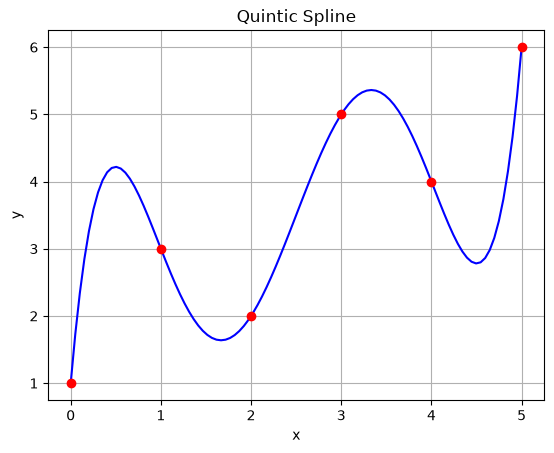

In [7]:
# Ejercicio 17.6: Ajuste polinomial de grado 5

def my_quintic_spline(x, y, X):

    # Ajuste polinomial de grado 5
    coef = np.polyfit(x, y, 5)

    # Evaluar el polinomio
    Y = np.polyval(coef, X)

    return Y

x = np.array([0, 1, 2, 3, 4, 5])
y = np.array([1, 3, 2, 5, 4, 6])

X = np.linspace(0, 5, 100)

Y = my_quintic_spline(x, y, X)

plt.plot(X, Y, 'b')
plt.plot(x, y, 'ro')
plt.title("Quintic Spline")
plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.show()

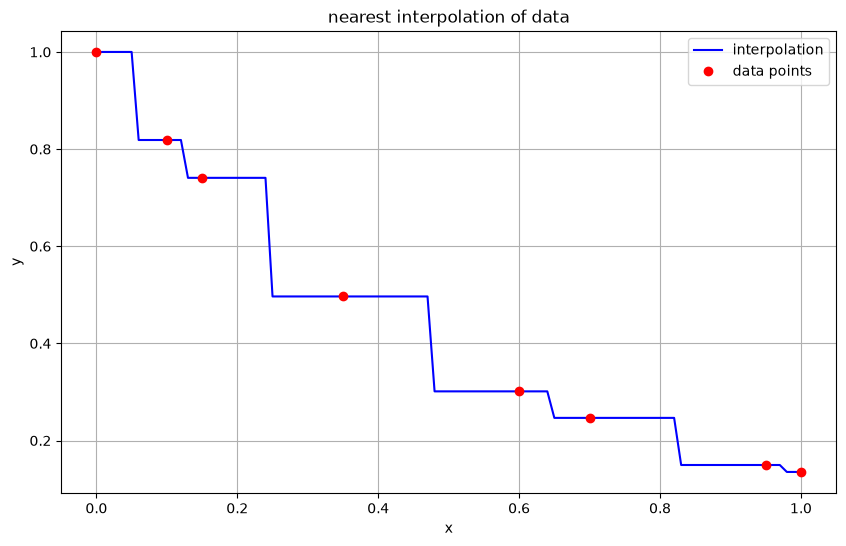

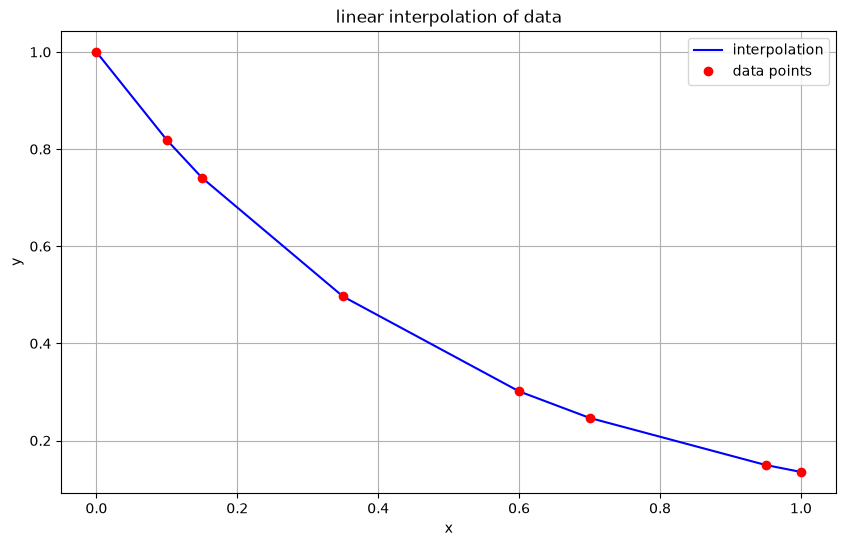

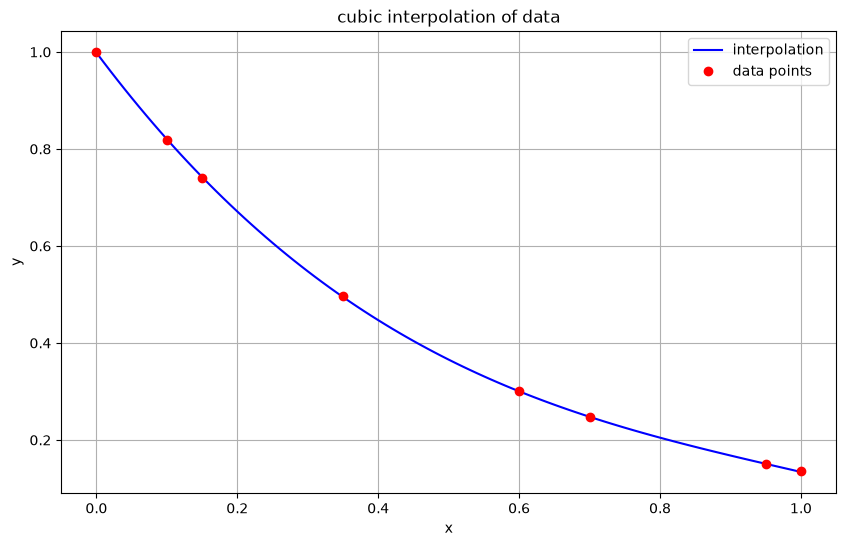

In [ ]:
# Ejercicio 17.7: Función para graficar los resultados de interpolación

def my_interp_plotter(x, y, X, option):
    if option == "nearest":
        Y = []
        for xp in X:
            indice = np.argmin(np.abs(x - xp))
            Y.append(y[indice])
        Y = np.array(Y)
    elif option == "linear":
        Y = []
        for xp in X:
            for i in range(len(x)-1):
                if x[i] <= xp <= x[i+1]:
                    yp = y[i] + (
                        (y[i+1]-y[i])
                        * (xp-x[i])
                        / (x[i+1]-x[i]))
                    Y.append(yp)
                    break
        Y = np.array(Y)
    elif option == "cubic":
        coef = np.polyfit(x, y, 3)
        Y = np.polyval(coef, X)
    else:
        print("Opción inválida")
        return
    plt.figure(figsize=(10,6))
    plt.plot(X, Y, "b", label="interpolation")
    plt.plot(x, y, "ro", label="data points")

    plt.xlabel("x")
    plt.ylabel("y")
    plt.title(f"{option} interpolation of data")
    plt.legend()
    plt.grid()

    plt.show()

# Ejemplo de uso de la función my_interp_plotter
x = np.array([0, .1, .15, .35, .6, .7, .95, 1])

y = np.array([    1,    0.8187,    0.7408,    0.4966,    0.3012,    0.2466,    0.1496,    0.1353])

X = np.linspace(0,1,101)

my_interp_plotter(x, y, X, "nearest")
my_interp_plotter(x, y, X, "linear")
my_interp_plotter(x, y, X, "cubic")

In [10]:
# Ejercicio 17.8: Splines cúbicos con condiciones de frontera derivadas

def my_D_cubic_spline(x, y, X, D):

    n = len(x)
    h = np.diff(x)

    A = np.zeros((n, n))
    b = np.zeros(n)

    # Condición de frontera izquierda
    A[0, 0] = 2 * h[0]
    A[0, 1] = h[0]

    b[0] = 6 * ((y[1] - y[0]) / h[0] - D)

    # Nodos interiores
    for i in range(1, n - 1):

        A[i, i - 1] = h[i - 1]
        A[i, i] = 2 * (h[i - 1] + h[i])
        A[i, i + 1] = h[i]

        b[i] = 6 * (
            (y[i + 1] - y[i]) / h[i]
            - (y[i] - y[i - 1]) / h[i - 1]
        )

    # Condición de frontera derecha
    A[n - 1, n - 2] = h[-1]
    A[n - 1, n - 1] = 2 * h[-1]

    b[n - 1] = 6 * (
        D - (y[-1] - y[-2]) / h[-1]
    )

    M = np.linalg.solve(A, b)

    if np.isscalar(X):
        X = np.array([X])

    Y = np.zeros(len(X))

    for k, xp in enumerate(X):

        for i in range(n - 1):

            if x[i] <= xp <= x[i + 1]:

                hi = x[i + 1] - x[i]

                Y[k] = (
                    M[i] * (x[i + 1] - xp) ** 3 / (6 * hi)
                    + M[i + 1] * (xp - x[i]) ** 3 / (6 * hi)
                    + (y[i] / hi - M[i] * hi / 6) * (x[i + 1] - xp)
                    + (y[i + 1] / hi - M[i + 1] * hi / 6) * (xp - x[i])
                )

                break

    return Y[0] if len(Y) == 1 else Y

# Ejemplo de prueba
x = [0, 1, 2, 3, 4]
y = [0, 0, 1, 0, 0]

X = np.linspace(0, 4, 101)

Y = my_D_cubic_spline(x, y, 1.5, 1)

print(Y)

0.5401785714285714


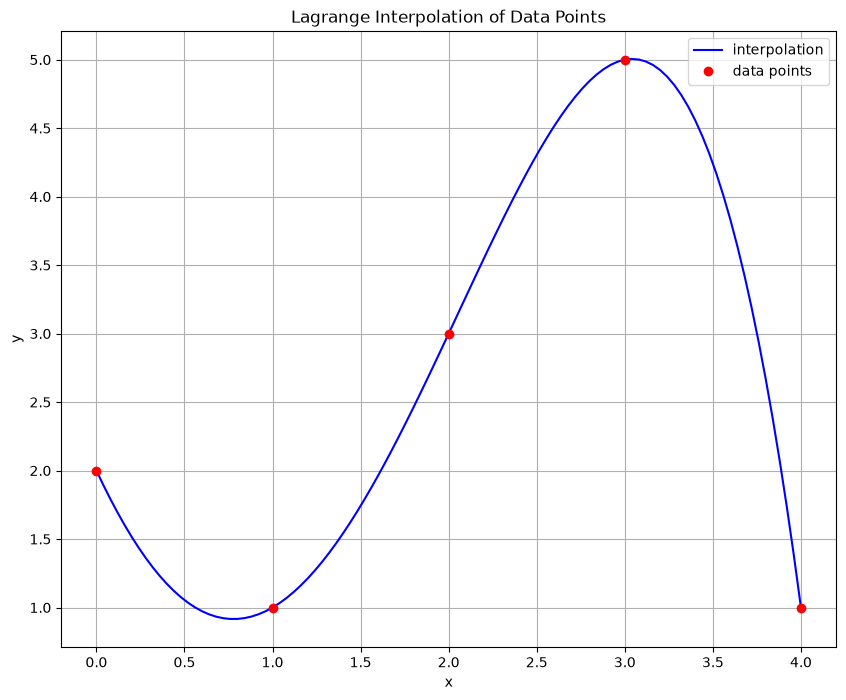

In [12]:
# Ejercicio 17.9: Interpolación de Lagrange
def my_lagrange(x, y, X):

    x = np.array(x, dtype=float)
    y = np.array(y, dtype=float)

    if np.isscalar(X):
        X = np.array([X])

    Y = np.zeros(len(X))

    for k in range(len(X)):

        suma = 0

        for i in range(len(x)):

            producto = 1

            for j in range(len(x)):

                if i != j:

                    producto *= (
                        (X[k] - x[j])
                        / (x[i] - x[j])
                    )

            suma += y[i] * producto

        Y[k] = suma

    return Y

# Ejemplo de prueba
import numpy as np
import matplotlib.pyplot as plt

x = [0, 1, 2, 3, 4]
y = [2, 1, 3, 5, 1]

X = np.linspace(0, 4, 101)

Y = my_lagrange(x, y, X)

plt.figure(figsize=(10,8))

plt.plot(X, Y, "b", label="interpolation")
plt.plot(x, y, "ro", label="data points")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Lagrange Interpolation of Data Points")

plt.legend()
plt.grid()
plt.show()

Coeficientes:
[ 2.    -1.     1.5   -0.5   -0.125]


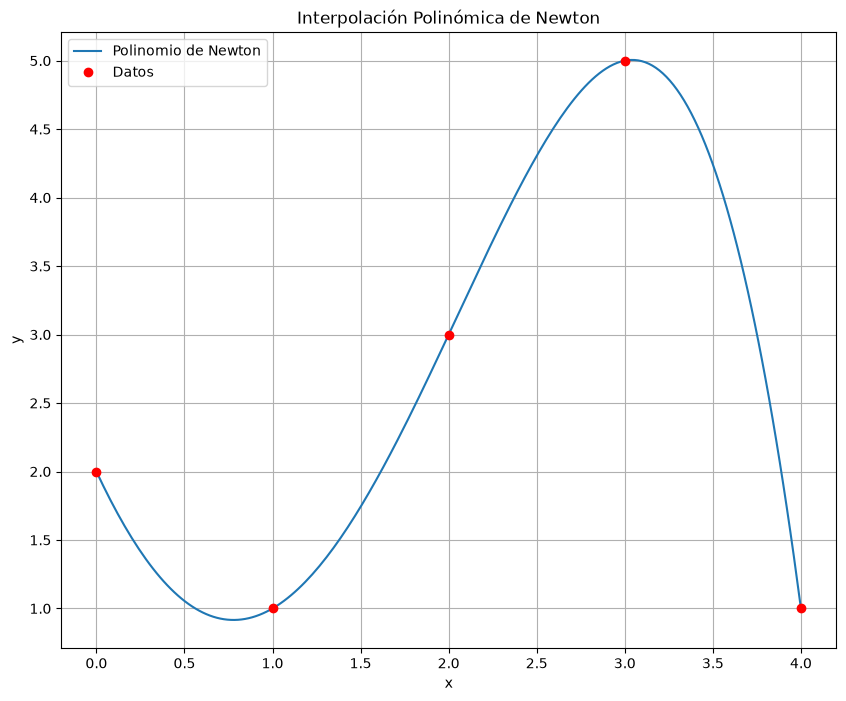

In [13]:
# Ejercicio 17.10: Interpolación de Newton

def divided_diff(x, y):

    n = len(y)

    coef = np.zeros((n, n))

    coef[:, 0] = y

    for j in range(1, n):

        for i in range(n - j):

            coef[i][j] = (
                coef[i + 1][j - 1]
                - coef[i][j - 1]
            ) / (x[i + j] - x[i])

    return coef


def newton_poly(coef, x_data, x):

    n = len(x_data) - 1

    p = coef[n]

    for k in range(1, n + 1):

        p = coef[n - k] + (x - x_data[n - k]) * p

    return p


# Datos del ejercicio

x = np.array([0, 1, 2, 3, 4], dtype=float)
y = np.array([2, 1, 3, 5, 1], dtype=float)

# Coeficientes de Newton
a_s = divided_diff(x, y)[0, :]

print("Coeficientes:")
print(a_s)

# Puntos para graficar
x_new = np.linspace(0, 4, 200)

y_new = newton_poly(a_s, x, x_new)

# Gráfico
plt.figure(figsize=(10, 8))

plt.plot(x_new, y_new,
         label="Polinomio de Newton")

plt.plot(x, y,
         "ro",
         label="Datos")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Interpolación Polinómica de Newton")

plt.grid()
plt.legend()

plt.show()